In [58]:
import pandas as pd
import numpy as np 

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import (KMeans,
                             DBSCAN)
from sklearn.decomposition import PCA

from sklearn.metrics import(silhouette_score,
                            davies_bouldin_score)

In [19]:
data= pd.read_csv("d:\\project\\15. Clustering\\EastWestAirlines.csv")

In [20]:
data

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1
...,...,...,...,...,...,...,...,...,...,...,...,...
3994,4017,18476,0,1,1,1,8525,4,200,1,1403,1
3995,4018,64385,0,1,1,1,981,5,0,0,1395,1
3996,4019,73597,0,3,1,1,25447,8,0,0,1402,1
3997,4020,54899,0,1,1,1,500,1,500,1,1401,0


In [21]:
df=data.copy()

In [22]:
df.head()

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


In [23]:
df.describe()

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
count,3999.000000,3.999000e+03,3999.000000,3999.000000,3999.000000,3999.000000,3999.000000,3999.00000,3999.000000,3999.000000,3999.00000,3999.000000
mean,2014.819455,7.360133e+04,144.114529,2.059515,1.014504,1.012253,17144.846212,11.60190,460.055764,1.373593,4118.55939,0.370343
std,1160.764358,1.007757e+05,773.663804,1.376919,0.147650,0.195241,24150.967826,9.60381,1400.209171,3.793172,2065.13454,0.482957
min,1.000000,0.000000e+00,0.000000,1.000000,1.000000,1.000000,0.000000,0.00000,0.000000,0.000000,2.00000,0.000000
25%,1010.500000,1.852750e+04,0.000000,1.000000,1.000000,1.000000,1250.000000,3.00000,0.000000,0.000000,2330.00000,0.000000
50%,2016.000000,4.309700e+04,0.000000,1.000000,1.000000,1.000000,7171.000000,12.00000,0.000000,0.000000,4096.00000,0.000000
75%,3020.500000,9.240400e+04,0.000000,3.000000,1.000000,1.000000,23800.500000,17.00000,311.000000,1.000000,5790.50000,1.000000
max,4021.000000,1.704838e+06,11148.000000,5.000000,3.000000,5.000000,263685.000000,86.00000,30817.000000,53.000000,8296.00000,1.000000


In [24]:
df.columns

Index(['ID#', 'Balance', 'Qual_miles', 'cc1_miles', 'cc2_miles', 'cc3_miles',
       'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12',
       'Days_since_enroll', 'Award?'],
      dtype='str')

In [25]:
df.columns

Index(['ID#', 'Balance', 'Qual_miles', 'cc1_miles', 'cc2_miles', 'cc3_miles',
       'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12',
       'Days_since_enroll', 'Award?'],
      dtype='str')

In [26]:
df.shape

(3999, 12)

In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ID#                3999 non-null   int64
 1   Balance            3999 non-null   int64
 2   Qual_miles         3999 non-null   int64
 3   cc1_miles          3999 non-null   int64
 4   cc2_miles          3999 non-null   int64
 5   cc3_miles          3999 non-null   int64
 6   Bonus_miles        3999 non-null   int64
 7   Bonus_trans        3999 non-null   int64
 8   Flight_miles_12mo  3999 non-null   int64
 9   Flight_trans_12    3999 non-null   int64
 10  Days_since_enroll  3999 non-null   int64
 11  Award?             3999 non-null   int64
dtypes: int64(12)
memory usage: 375.0 KB


In [28]:
df.isnull().sum()

ID#                  0
Balance              0
Qual_miles           0
cc1_miles            0
cc2_miles            0
cc3_miles            0
Bonus_miles          0
Bonus_trans          0
Flight_miles_12mo    0
Flight_trans_12      0
Days_since_enroll    0
Award?               0
dtype: int64

In [29]:
df.dtypes

ID#                  int64
Balance              int64
Qual_miles           int64
cc1_miles            int64
cc2_miles            int64
cc3_miles            int64
Bonus_miles          int64
Bonus_trans          int64
Flight_miles_12mo    int64
Flight_trans_12      int64
Days_since_enroll    int64
Award?               int64
dtype: object

In [30]:
df.duplicated().sum()

np.int64(0)

In [31]:
df.columns

Index(['ID#', 'Balance', 'Qual_miles', 'cc1_miles', 'cc2_miles', 'cc3_miles',
       'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12',
       'Days_since_enroll', 'Award?'],
      dtype='str')

In [40]:
df = df.drop('ID#', axis=1,)

In [37]:
df.rename(columns={
    'Award?' : 'Award'
})

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1
...,...,...,...,...,...,...,...,...,...,...,...,...
3994,4017,18476,0,1,1,1,8525,4,200,1,1403,1
3995,4018,64385,0,1,1,1,981,5,0,0,1395,1
3996,4019,73597,0,3,1,1,25447,8,0,0,1402,1
3997,4020,54899,0,1,1,1,500,1,500,1,1401,0


In [41]:
df.columns

Index(['Balance', 'Qual_miles', 'cc1_miles', 'cc2_miles', 'cc3_miles',
       'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12',
       'Days_since_enroll', 'Award'],
      dtype='str')

In [42]:
numerical_cols = df.select_dtypes(include=np.number).columns

categorical_cols =df.select_dtypes(include='object').columns

print("Numerical Columns:", numerical_cols)
print("Categorical Columns:", categorical_cols)

Numerical Columns: Index(['Balance', 'Qual_miles', 'cc1_miles', 'cc2_miles', 'cc3_miles',
       'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12',
       'Days_since_enroll', 'Award'],
      dtype='str')
Categorical Columns: Index([], dtype='str')


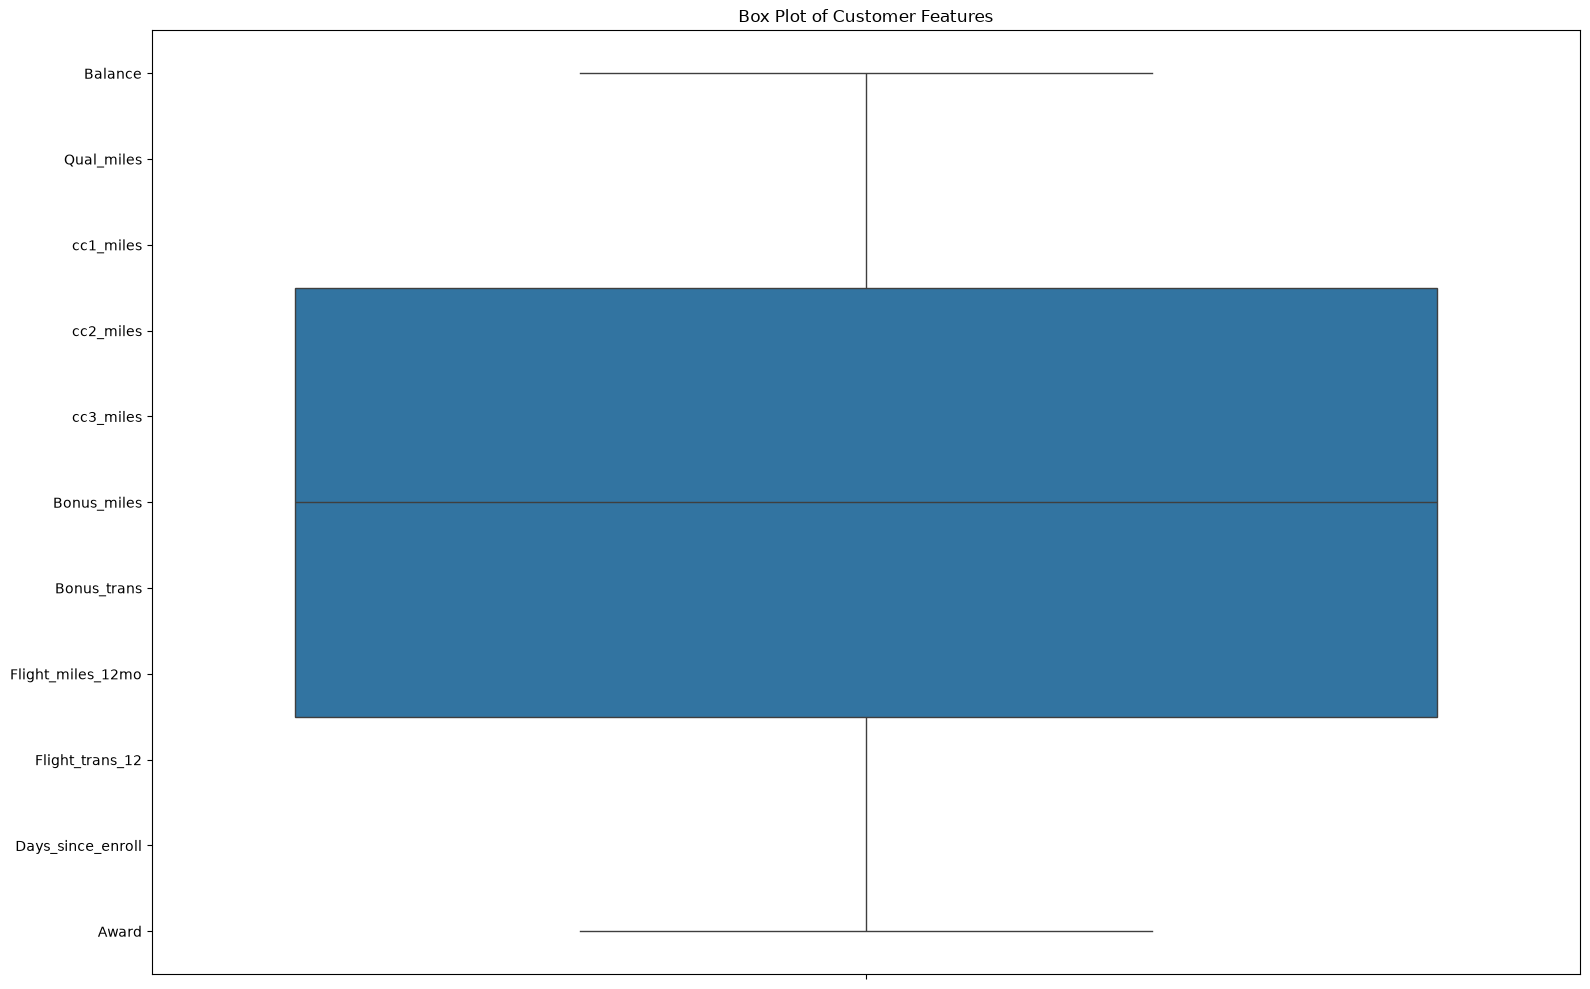

In [43]:
plt.figure(figsize=(16, 10))

sns.boxplot(data=numerical_cols)

plt.xticks(rotation=45)
plt.title("Box Plot of Customer Features")
plt.tight_layout()
plt.show()

In [45]:
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_count = ((df < lower) | (df > upper)).sum()

outlier_count

Balance              266
Qual_miles           226
cc1_miles              0
cc2_miles             43
cc3_miles             18
Bonus_miles          280
Bonus_trans           63
Flight_miles_12mo    569
Flight_trans_12      565
Days_since_enroll      0
Award                  0
dtype: int64

In [46]:
df = df.clip(lower=lower, upper=upper, axis=1)

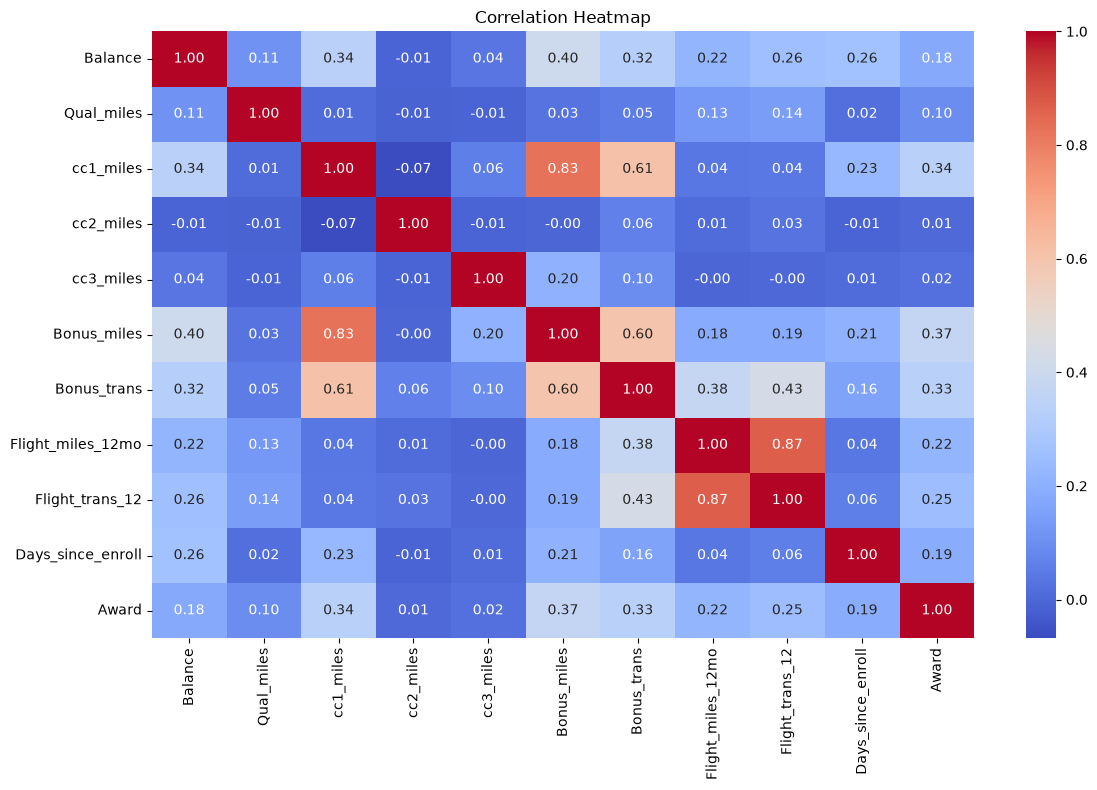

In [44]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

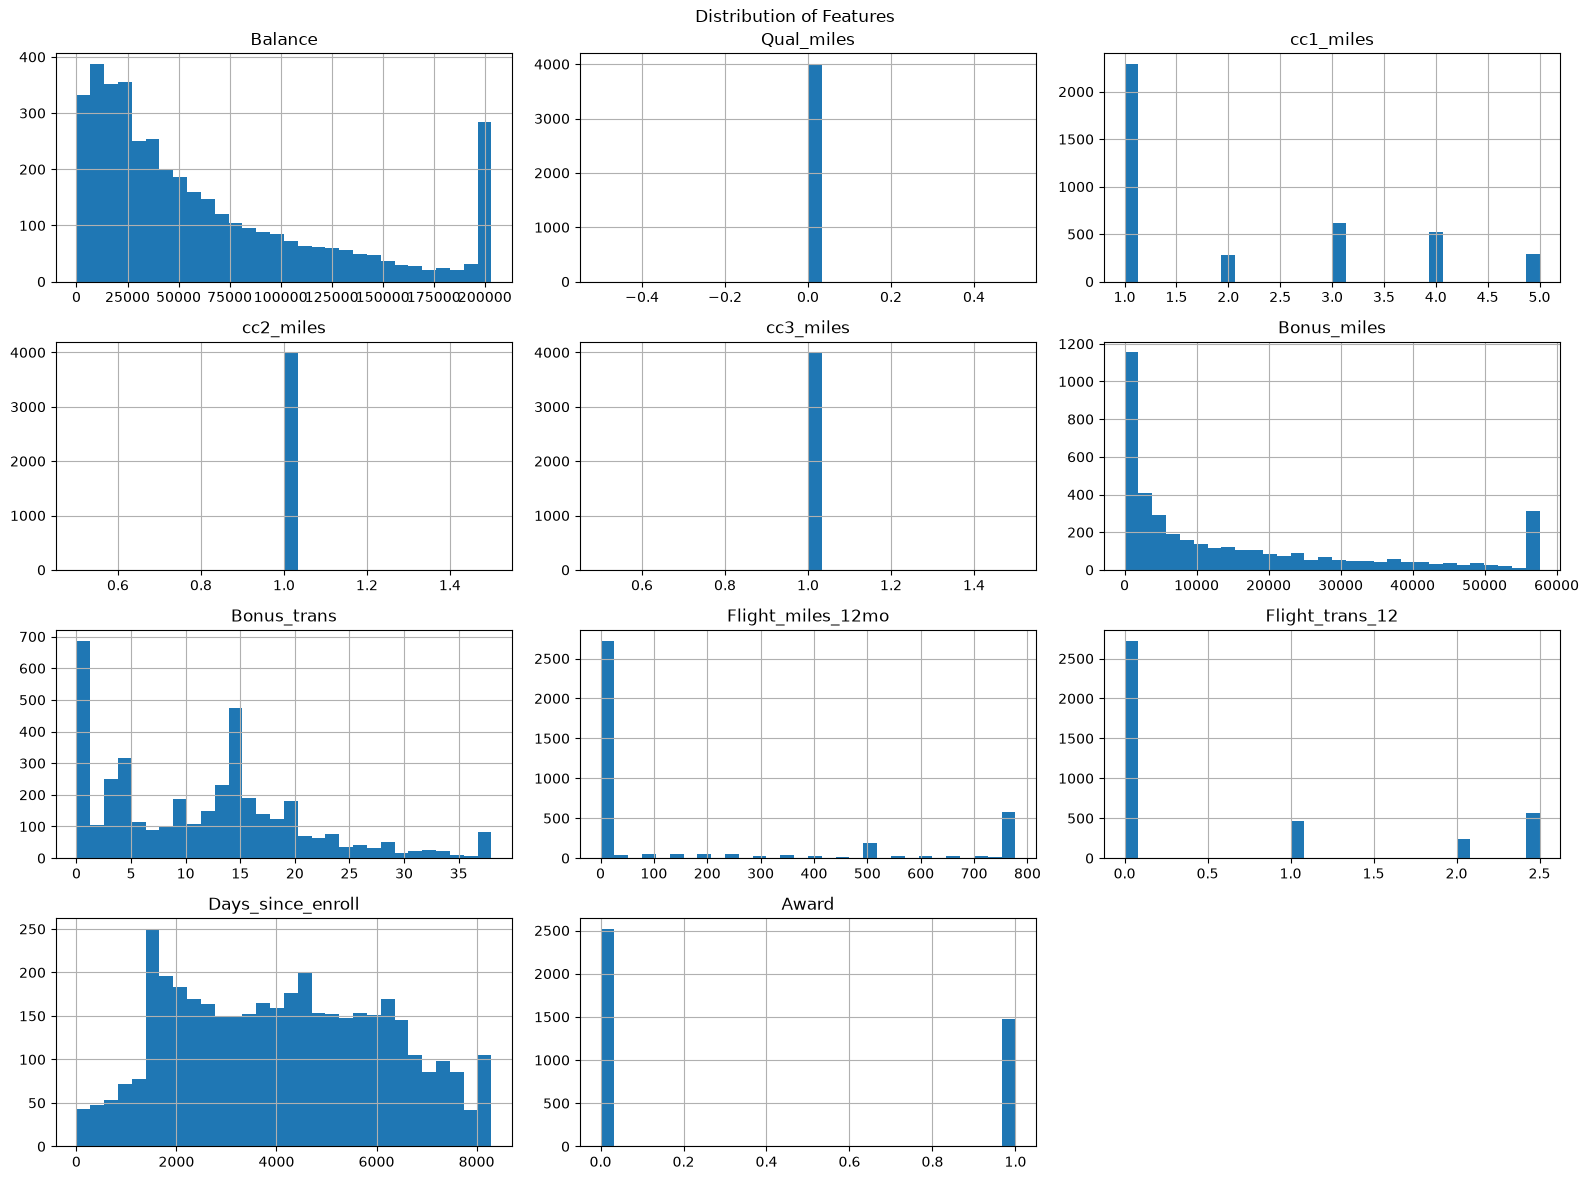

In [47]:
df.hist(figsize=(16, 12), bins=30)

plt.suptitle("Distribution of Features")
plt.tight_layout()
plt.show()

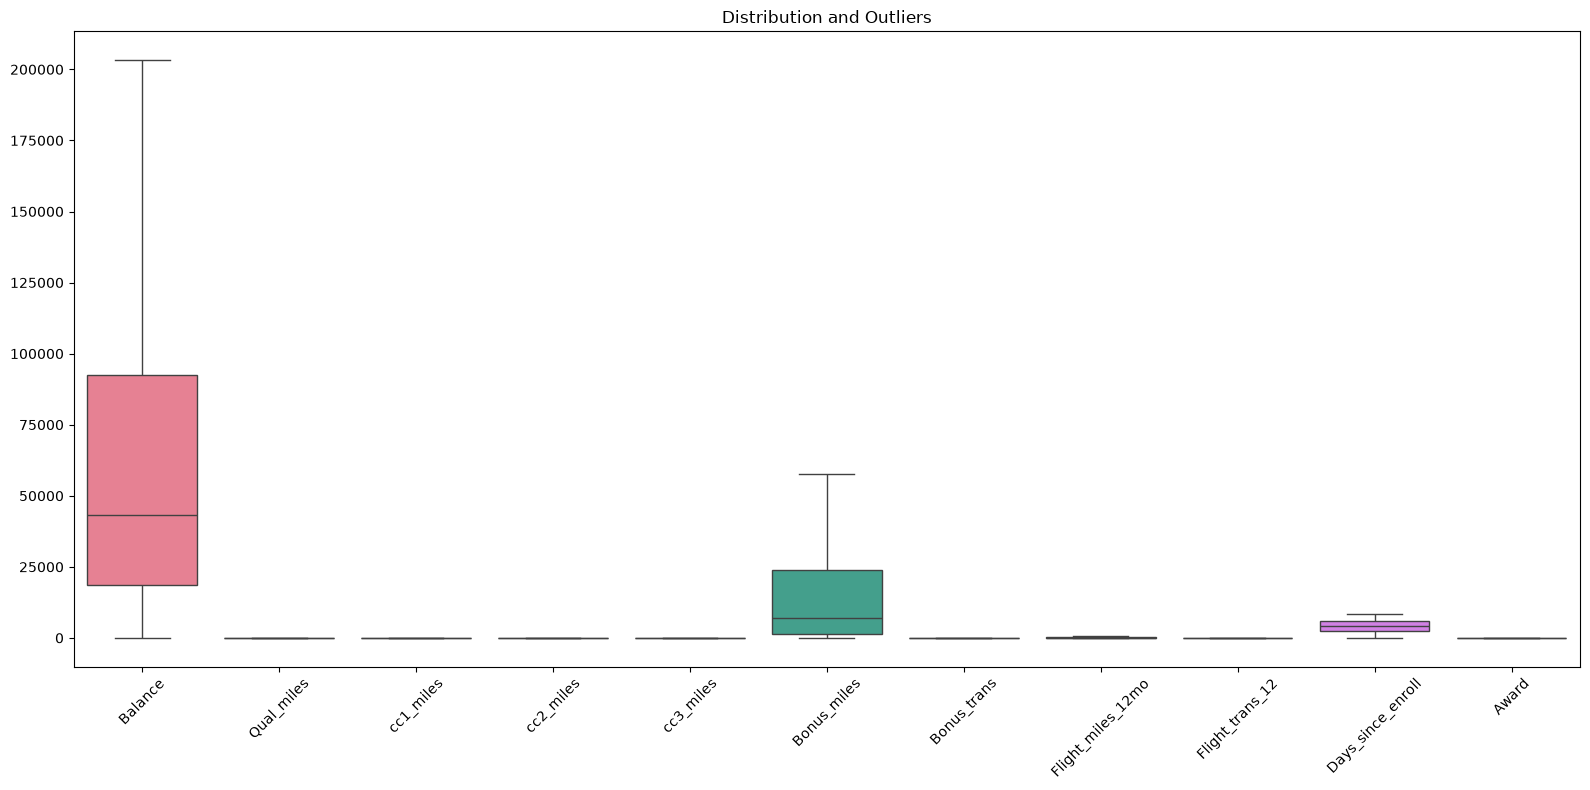

In [48]:
plt.figure(figsize=(16, 8))

sns.boxplot(data=df)

plt.xticks(rotation=45)
plt.title("Distribution and Outliers")
plt.tight_layout()
plt.show()

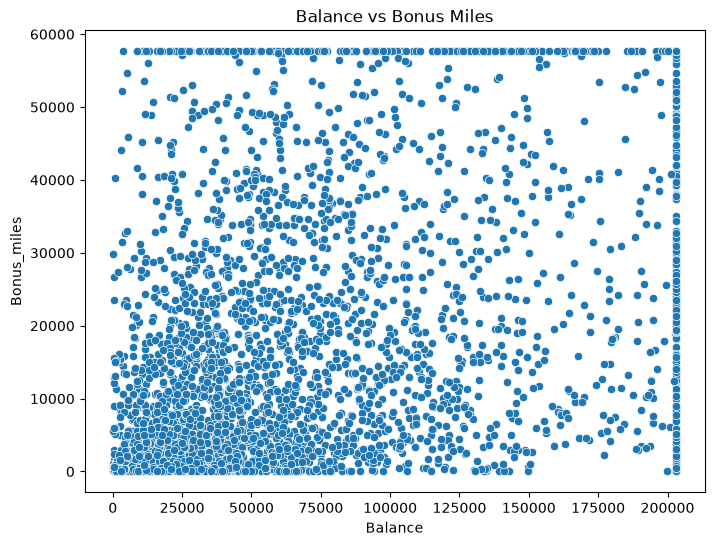

In [49]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Balance',
    y='Bonus_miles'
)

plt.title("Balance vs Bonus Miles")
plt.show()

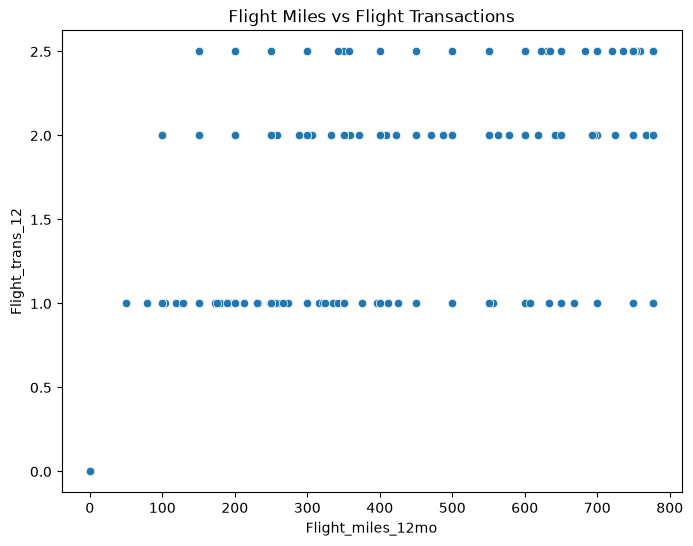

In [50]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Flight_miles_12mo',
    y='Flight_trans_12'
)

plt.title("Flight Miles vs Flight Transactions")
plt.show()

In [51]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(df)

scaled_df = pd.DataFrame(
    scaled_data,
    columns=df.columns
)

scaled_df.head()

,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award
0,-0.607258,0.0,-0.769578,0.0,0.0,-0.843091,-1.148854,-0.604313,-0.626143,1.395454,-0.766919
1,-0.758947,0.0,-0.769578,0.0,0.0,-0.840822,-1.039133,-0.604313,-0.626143,1.379957,-0.766919
2,-0.382070,0.0,-0.769578,0.0,0.0,-0.624581,-0.819689,-0.604313,-0.626143,1.411920,-0.766919
3,-0.835106,0.0,-0.769578,0.0,0.0,-0.825052,-1.148854,-0.604313,-0.626143,1.372208,-0.766919
4,0.579265,0.0,1.409471,0.0,0.0,1.543191,1.594189,2.034489,2.020176,1.363975,1.303918


In [55]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_data)
    wcss.append(kmeans.inertia_)

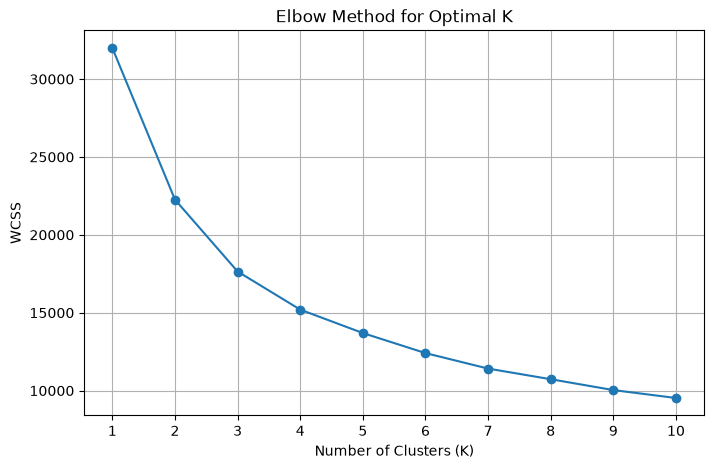

In [56]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method for Optimal K')
plt.xticks(range(1, 11))
plt.grid()
plt.show()

In [57]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

kmeans_labels = kmeans.fit_predict(scaled_data)

In [59]:
df['KMeans_Cluster'] = kmeans_labels

print(df['KMeans_Cluster'].value_counts())


KMeans_Cluster
0    2080
2    1095
1     824
Name: count, dtype: int64


In [61]:
eps_values = [0.3, 0.5, 0.7, 1.0]
min_samples_values = [3, 5, 7, 10]

for eps in eps_values:
    for min_samples in min_samples_values:

        dbscan = DBSCAN(eps=eps, min_samples=min_samples)

        labels = dbscan.fit_predict(scaled_data)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)

        print("Epsilon:", eps)
        print("Min Samples:", min_samples)
        print("Number of Clusters:", n_clusters)
        print("Number of Noise Points:", n_noise)
        print("-------------------------")

Epsilon: 0.3
Min Samples: 3
Number of Clusters: 96
Number of Noise Points: 2326
-------------------------
Epsilon: 0.3
Min Samples: 5
Number of Clusters: 22
Number of Noise Points: 2699
-------------------------
Epsilon: 0.3
Min Samples: 7
Number of Clusters: 10
Number of Noise Points: 2845
-------------------------
Epsilon: 0.3
Min Samples: 10
Number of Clusters: 3
Number of Noise Points: 2967
-------------------------
Epsilon: 0.5
Min Samples: 3
Number of Clusters: 96
Number of Noise Points: 1355
-------------------------
Epsilon: 0.5
Min Samples: 5
Number of Clusters: 33
Number of Noise Points: 1741
-------------------------
Epsilon: 0.5
Min Samples: 7
Number of Clusters: 20
Number of Noise Points: 1951
-------------------------
Epsilon: 0.5
Min Samples: 10
Number of Clusters: 11
Number of Noise Points: 2231
-------------------------
Epsilon: 0.7
Min Samples: 3
Number of Clusters: 78
Number of Noise Points: 780
-------------------------
Epsilon: 0.7
Min Samples: 5
Number of Clusters

In [62]:
dbscan = DBSCAN(eps=0.5, min_samples=5)

dbscan_labels = dbscan.fit_predict(scaled_data)

In [63]:
print("K-Means Silhouette Score:",
      silhouette_score(scaled_data, kmeans_labels))

print("K-Means Davies-Bouldin Index:",
      davies_bouldin_score(scaled_data, kmeans_labels))

K-Means Silhouette Score: 0.30871467844360884
K-Means Davies-Bouldin Index: 1.3751821489415164


In [64]:
# Exclude noise points for evaluation
mask = dbscan_labels != -1

dbscan_valid_labels = dbscan_labels[mask]
X_dbscan_valid = scaled_data[mask]

if len(set(dbscan_valid_labels)) >= 2:
    print("DBSCAN Silhouette Score:",
          silhouette_score(X_dbscan_valid, dbscan_valid_labels))

    print("DBSCAN Davies-Bouldin Index:",
          davies_bouldin_score(X_dbscan_valid, dbscan_valid_labels))
else:
    print("DBSCAN cannot be evaluated: Less than 2 clusters found.")

DBSCAN Silhouette Score: 0.11862726845782659
DBSCAN Davies-Bouldin Index: 0.9485115279776021


In [65]:
print("K-Means Clusters:", len(set(kmeans_labels)))

print("DBSCAN Clusters:",
      len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0))

print("DBSCAN Noise Points:", list(dbscan_labels).count(-1))

K-Means Clusters: 3
DBSCAN Clusters: 33
DBSCAN Noise Points: 1741


In [66]:
# Analyse characteristics of each K-Means cluster

df.groupby('KMeans_Cluster').mean(numeric_only=True)

,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award
KMeans_Cluster,,,,,,,,,,,
0,34723.407091,0.0,1.160577,1.0,1.0,3751.946755,6.226923,35.188462,0.138462,3626.206250,0.162500
1,96884.322209,0.0,2.218447,1.0,1.0,20941.373180,16.748786,696.962985,2.239684,4510.593447,0.652913
2,94021.375571,0.0,3.647489,1.0,1.0,33395.224886,17.459361,58.954338,0.211872,4758.795434,0.552511


In [67]:
df['KMeans_Cluster'].value_counts()

KMeans_Cluster
0    2080
2    1095
1     824
Name: count, dtype: int64

In [69]:
df['DBSCAN_Cluster'] = dbscan_labels

In [70]:
# Analyse characteristics of each DBSCAN cluster

df.groupby('DBSCAN_Cluster').mean(numeric_only=True)

,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award,KMeans_Cluster
DBSCAN_Cluster,,,,,,,,,,,,
-1,99655.372774,0.0,2.64618,1.0,1.0,25346.676910,16.553705,347.463814,1.159104,4676.196439,0.568064,1.159678
0,24766.411811,0.0,1.00000,1.0,1.0,1900.448031,4.685039,0.000000,0.000000,3442.424409,0.000000,0.000000
1,26156.828729,0.0,1.00000,1.0,1.0,3016.370166,4.922652,0.000000,0.000000,4040.839779,1.000000,0.000000
2,77173.053571,0.0,4.00000,1.0,1.0,33340.125000,14.910714,0.000000,0.000000,4560.821429,0.000000,2.000000
3,132880.500000,0.0,4.00000,1.0,1.0,32284.125000,15.000000,0.000000,0.000000,6298.250000,0.000000,2.000000
4,72525.639594,0.0,3.00000,1.0,1.0,17480.598985,14.365482,0.000000,0.000000,4002.634518,0.000000,1.370558
5,14713.142857,0.0,2.00000,1.0,1.0,8238.571429,13.285714,0.000000,0.000000,7631.571429,1.000000,0.285714
6,31227.177966,0.0,3.00000,1.0,1.0,17594.161017,14.762712,0.000000,0.000000,4286.093220,1.000000,1.949153
7,203218.750000,0.0,5.00000,1.0,1.0,57626.250000,26.800000,777.500000,2.500000,6978.600000,1.000000,1.000000


In [71]:
df['DBSCAN_Cluster'].value_counts()

DBSCAN_Cluster
-1     1741
 0     1270
 4      197
 1      181
 6      118
 10      98
 2       56
 18      48
 25      43
 24      23
 12      22
 23      22
 17      20
 9       19
 8       19
 11      15
 30       9
 3        8
 5        7
 16       7
 15       7
 27       7
 26       7
 19       6
 7        5
 14       5
 13       5
 21       5
 22       5
 31       5
 28       5
 29       5
 32       5
 20       4
Name: count, dtype: int64

In [72]:
df['DBSCAN_Cluster'].value_counts()

DBSCAN_Cluster
-1     1741
 0     1270
 4      197
 1      181
 6      118
 10      98
 2       56
 18      48
 25      43
 24      23
 12      22
 23      22
 17      20
 9       19
 8       19
 11      15
 30       9
 3        8
 5        7
 16       7
 15       7
 27       7
 26       7
 19       6
 7        5
 14       5
 13       5
 21       5
 22       5
 31       5
 28       5
 29       5
 32       5
 20       4
Name: count, dtype: int64

In [73]:
print("K-Means Cluster Distribution:")
print(df['KMeans_Cluster'].value_counts())

print("\nDBSCAN Cluster Distribution:")
print(df['DBSCAN_Cluster'].value_counts())

K-Means Cluster Distribution:
KMeans_Cluster
0    2080
2    1095
1     824
Name: count, dtype: int64

DBSCAN Cluster Distribution:
DBSCAN_Cluster
-1     1741
 0     1270
 4      197
 1      181
 6      118
 10      98
 2       56
 18      48
 25      43
 24      23
 12      22
 23      22
 17      20
 9       19
 8       19
 11      15
 30       9
 3        8
 5        7
 16       7
 15       7
 27       7
 26       7
 19       6
 7        5
 14       5
 13       5
 21       5
 22       5
 31       5
 28       5
 29       5
 32       5
 20       4
Name: count, dtype: int64


In [75]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(scaled_data)

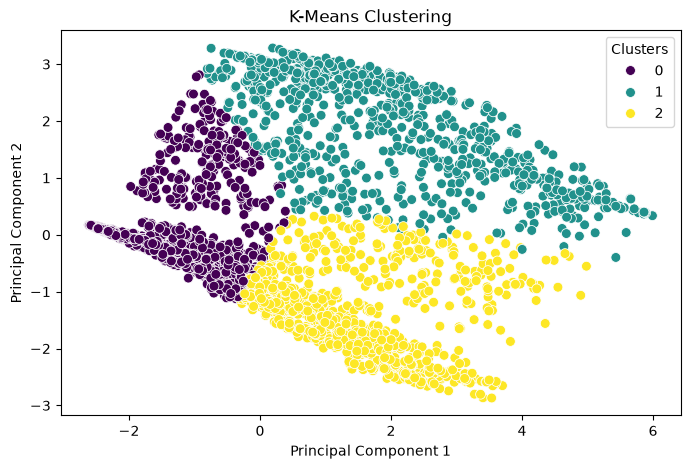

In [76]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=kmeans_labels,
    palette='viridis',
    s=50
)

plt.title('K-Means Clustering')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Clusters')
plt.show()

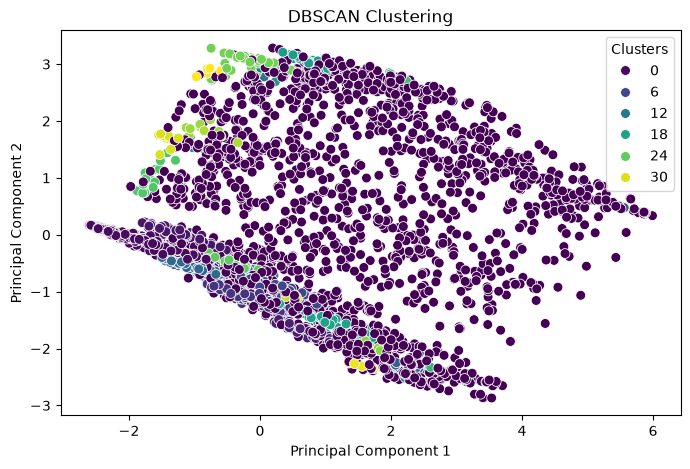

In [77]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=dbscan_labels,
    palette='viridis',
    s=50
)

plt.title('DBSCAN Clustering')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Clusters')
plt.show()

In [79]:
kmeans_silhouette = silhouette_score(scaled_data, kmeans_labels)

print("K-Means Silhouette Score:", kmeans_silhouette)

K-Means Silhouette Score: 0.30871467844360884


In [82]:
# Remove noise points
mask = dbscan_labels != -1

dbscan_data = scaled_data[mask]
dbscan_valid_labels = dbscan_labels[mask]

# Check whether at least 2 clusters exist
if len(set(dbscan_valid_labels)) >= 2:

    dbscan_silhouette = silhouette_score(
        dbscan_data,
        dbscan_valid_labels
    )

    print("DBSCAN Silhouette Score:", dbscan_silhouette)

else:
    print("Silhouette Score cannot be calculated because DBSCAN identified less than 2 clusters.")

DBSCAN Silhouette Score: 0.11862726845782659


In [83]:
print("K-Means Silhouette Score:", kmeans_silhouette)

if len(set(dbscan_valid_labels)) >= 2:
    print("DBSCAN Silhouette Score:", dbscan_silhouette)

K-Means Silhouette Score: 0.30871467844360884
DBSCAN Silhouette Score: 0.11862726845782659
